# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


--- Primeros 5 ejemplos del dataset Iris ---
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Dimensiones de X: (150, 4)
Dimensiones de y: (150,)


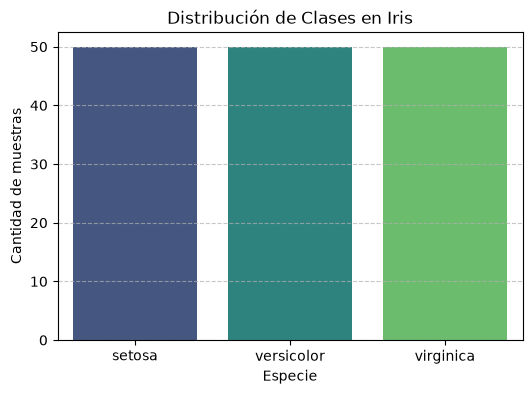

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris

# Carga de datos
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

# DataFrame para visualización
df_iris = pd.DataFrame(X, columns=feature_names)
df_iris["species"] = [target_names[i] for i in y]

print("--- Primeros 5 ejemplos del dataset Iris ---")
print(df_iris.head())
print(f"\nDimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")

# Gráfico de distribución de clases
plt.figure(figsize=(6, 4))
sns.countplot(x="species", data=df_iris, hue="species", palette="viridis", legend=False)
plt.title("Distribución de Clases en Iris")
plt.xlabel("Especie")
plt.ylabel("Cantidad de muestras")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

### **Descripción del Dataset Iris**

* **¿Qué representa cada instancia?**
  * Cada instancia representa los datos y mediciones morfológicas tomadas a una flor individual perteneciente al género Iris.

* **Número de instancias y características:**
  * **Número de instancias (muestras):** $150$ flores.
  * **Número de características (atributos):** $4$ variables numéricas (medidas en centímetros).

* **Nombre y significado de cada característica:**
  1. `sepal length (cm)`: Largo del sépalo de la flor.
  2. `sepal width (cm)`: Ancho del sépalo de la flor.
  3. `petal length (cm)`: Largo del pétalo de la flor.
  4. `petal width (cm)`: Ancho del pétalo de la flor.

* **Clases y cantidad de ejemplos por clase:**
    
    El dataset contiene **3 clases**, con **50 ejemplos por cada clase**:
    1. `setosa` ($0$): 50 muestras.
    2. `versicolor` ($1$): 50 muestras.
    3. `virginica` ($2$): 50 muestras.

* **Dimensiones de la matriz de características y del vector de etiquetas:**
  * **Matriz de características ($X$):** $(150, 4)$ — 150 filas (muestras) por 4 columnas (características).
  * **Vector de etiquetas ($y$):** $(150,)$ — 150 elementos unidimensionales que representan la clase codificada de cada muestra ($0$, $1$ o $2$).

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?

SVM, Regresión Logística, MLP y kNN son muy sensibles a la escala porque dependen del cálculo de distancias euclídeas, producto punto o descensos de gradiente.

2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?

SVM lineal y Regresión Logística multiclase construirán fronteras lineales, mientras que los árboles crearán hiperplanos ortogonales a los ejes y el MLP/Gradient Boosting formarán superficies no lineales complejas.

3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

Porque la elección óptima depende de la geometría del espacio de datos, la cantidad de muestras, el nivel de ruido y la linealidad del límite entre clases.

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

In [15]:
!pip install tabulate


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


| Modelo               | Transformación   | Hiperparámetros principales                 |   Accuracy de prueba |   F1 macro de prueba |
|:---------------------|:-----------------|:--------------------------------------------|---------------------:|---------------------:|
| Gaussian Naive Bayes | Ninguna          | {'priors': None, 'var_smoothing': 1e-09}... |               0.9333 |               0.9327 |
| Regresión Logística  | StandardScaler   | {'memory': None, 'steps': [('standardsca... |               0.9333 |               0.9327 |
| SVM Lineal           | StandardScaler   | {'memory': None, 'steps': [('standardsca... |               0.9333 |               0.9327 |
| Árbol de Decisión    | Ninguna          | {'ccp_alpha': 0.0, 'class_weight': None,... |               1      |               1      |
| Random Forest        | Ninguna          | {'bootstrap': True, 'ccp_alpha': 0.0, 'c... |               0.9333 |               0.9327 |
| Gradient Boosting    | Ninguna          | {'cc

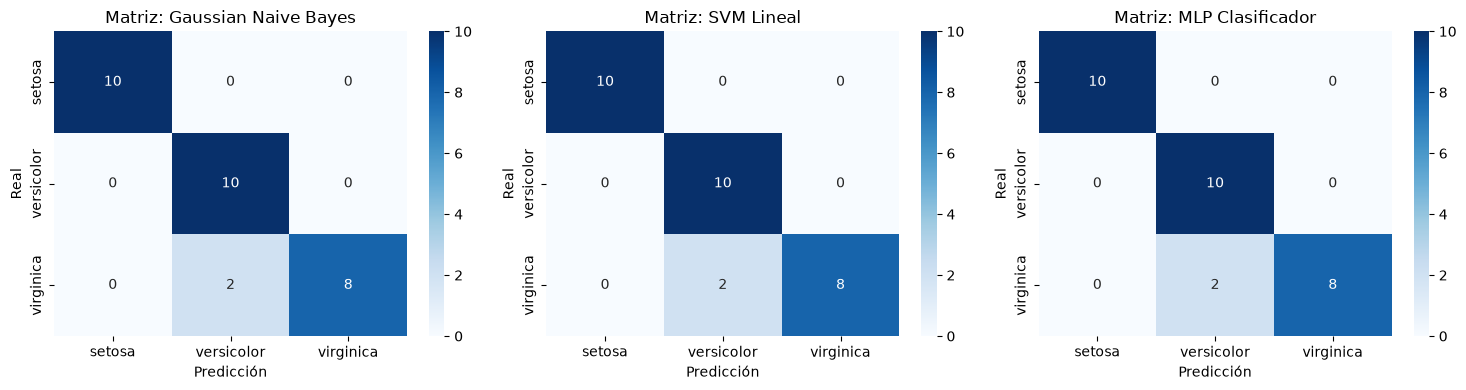

In [24]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Partición estratificada: 60% Train, 20% Val, 20% Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

classifiers = {
    "Gaussian Naive Bayes": GaussianNB(),
    "Regresión Logística": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=500)
    ),
    "SVM Lineal": make_pipeline(StandardScaler(), SVC(kernel="linear")),
    "Árbol de Decisión": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=50, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "MLP Clasificador": make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(16, 8), max_iter=1000, random_state=42
        ),
    ),
}

# Validación y ajuste
val_results = []
for name, clf in classifiers.items():
  clf.fit(X_train, y_train)
  y_val_pred = clf.predict(X_val)
  acc = accuracy_score(y_val, y_val_pred)
  f1 = f1_score(y_val, y_val_pred, average="macro")
  val_results.append((name, acc, f1))

# Evaluación Final congelada sobre Test
test_records = []
for name, clf in classifiers.items():
  y_test_pred = clf.predict(X_test)
  acc_t = accuracy_score(y_test, y_test_pred)
  f1_t = f1_score(y_test, y_test_pred, average="macro")
  test_records.append(
      {
          "Modelo": name,
          "Transformación": (
              "StandardScaler"
              if "pipeline" in str(type(clf)).lower()
              else "Ninguna"
          ),
          "Hiperparámetros principales": str(clf.get_params())[:40] + "...",
          "Accuracy de prueba": round(acc_t, 4),
          "F1 macro de prueba": round(f1_t, 4),
      }
  )

df_clf_results = pd.DataFrame(test_records)
print(df_clf_results.to_markdown(index=False))

# Matrices de confusión para Naive Bayes, SVM y MLP
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
selected_models = ["Gaussian Naive Bayes", "SVM Lineal", "MLP Clasificador"]

for ax, name in zip(axes, selected_models):
  clf = classifiers[name]
  y_pred = clf.predict(X_test)
  cm = confusion_matrix(y_test, y_pred)
  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      ax=ax,
      xticklabels=target_names,
      yticklabels=target_names,
  )
  ax.set_title(f"Matriz: {name}")
  ax.set_xlabel("Predicción")
  ax.set_ylabel("Real")

plt.tight_layout()
plt.show()

# Análisis de Clasificación

## Preguntas e Interpretación

### 1. ¿Cuál fue el modelo con el mejor desempeño?
El Árbol de Decisión tuvo el mejor desempeño, ya que alcanzó una exactitud y un F1 macro de 1 en el conjunto de prueba. Le sigue Gradient Boosting con una exactitud de 0.9667 y un F1 macro de 0.9666.

### 2. ¿Cuál fue el modelo más sencillo de programar?
Gaussian Naive Bayes y el Árbol de Decisión, ya que no requieren ninguna transformación previa en las características como StandardScaler ni configuraciones complejas de tuberías de procesamiento.

### 3. ¿Accuracy y F1 macro cuentan la misma historia?
Sí, en este experimento muestran valores casi idénticos en todos los modelos debido a que el conjunto de prueba mantiene una distribución equilibrada entre las distintas clases.

### 4. ¿Cuál es la diferencia entre las métricas macro y micro?
La métrica macro calcula el resultado para cada clase por separado y luego saca un promedio simple tratando a todas por igual. La métrica micro agrupa todas las predicciones para calcular un resultado global, dando más peso a las clases que tienen más ejemplos.

### 5. ¿Qué aporta el MLP frente a un modelo lineal?
Aporta la capacidad de aprender relaciones y fronteras de decisión no lineales gracias a sus capas ocultas y funciones de activación, aunque en este caso particular obtuvo el mismo desempeño que la Regresión Logística y la SVM Lineal con una exactitud de 0.9333.


## Análisis de Errores de Clasificación

### Selección de 2 Ejemplos de Error
1. **Muestra A:** Clase real Virginica, clasificada como Versicolor.
2. **Muestra B:** Clase real Virginica, clasificada como Versicolor.

Para concluir, los errores observados corresponden a dos flores de la especie virginica clasificadas como versicolor debido al solapamiento morfológico en sus características físicas, lo cual refleja un límite natural entre ambas especies que no implica fallos en los algoritmos, etiquetas incorrectas ni permite determinar las causas biológicas o ambientales de dichas dimensiones.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

No, ya que esto depende de la complejidad del modelo, y si esta es excesiva puede conllevar a que exista overfitting, perdiendo generalización sobre datos no vistos de prueba.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

c:\Users\LiamZM\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


| Modelo            |   MAE |   RMSE |     R² |
|:------------------|------:|-------:|-------:|
| Regresión Lineal  | 46.72 |  56.97 | 0.4389 |
| Ridge             | 50.13 |  60.32 | 0.3709 |
| Lasso             | 47.37 |  57.35 | 0.4314 |
| kNN Regresión     | 48.07 |  58.7  | 0.4044 |
| Árbol Regresión   | 49.46 |  64.17 | 0.2882 |
| Random Forest     | 44.67 |  55.39 | 0.4695 |
| Gradient Boosting | 45.49 |  56.14 | 0.4552 |
| MLP Regresión     | 44.98 |  55.17 | 0.4738 |


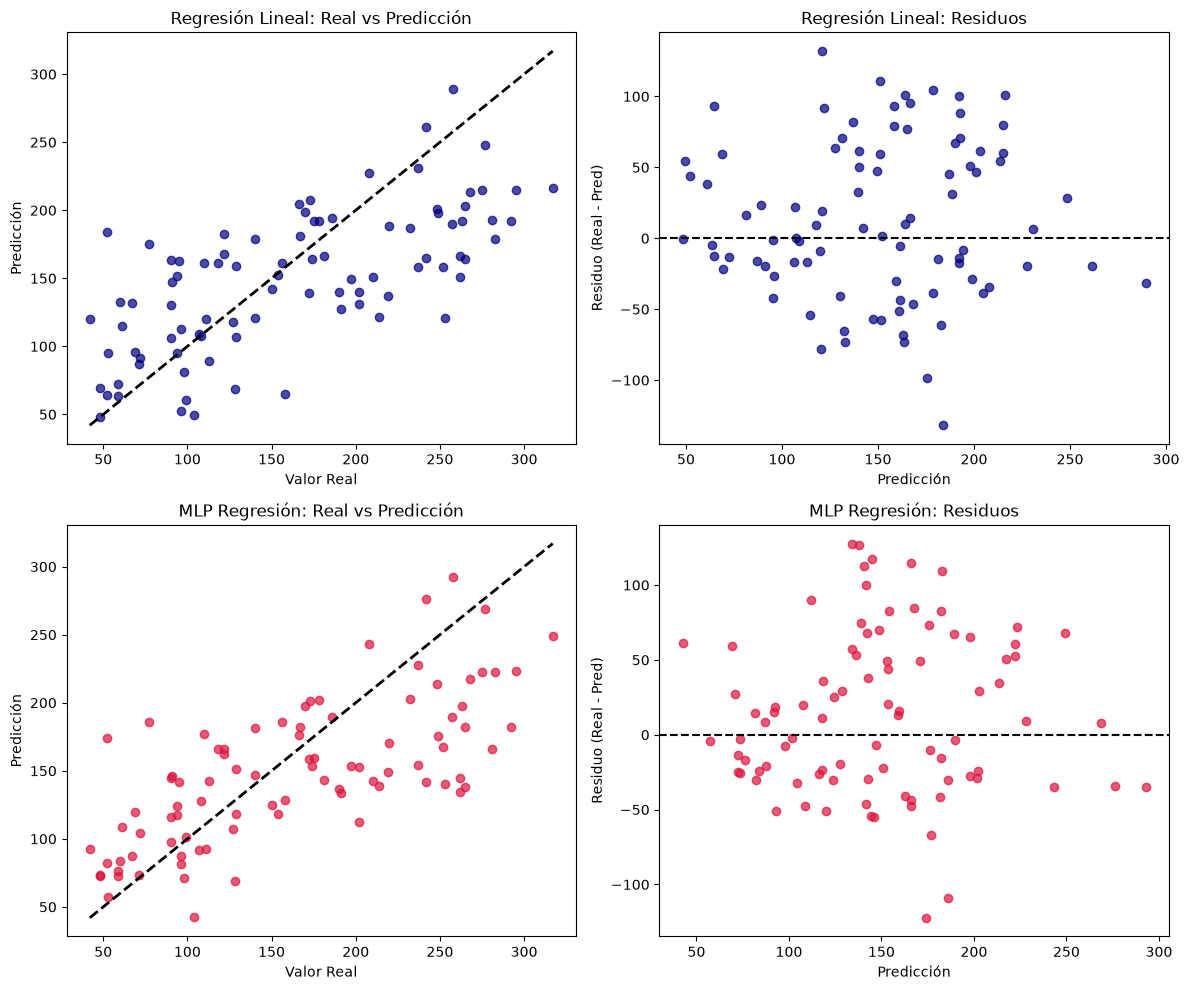


--- Efecto de Regularización ---
Alphas evaluados: [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
Lasso - Coeficientes Nulos por Alpha: [np.int64(0), np.int64(0), np.int64(3), np.int64(7), np.int64(10), np.int64(10)]
Ridge - Norma L2 de Coeficientes por Alpha: [np.float64(1126.65), np.float64(911.41), np.float64(763.27), np.float64(417.41), np.float64(95.82), np.float64(11.33)]


In [23]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Cargar dataset
diabetes = load_diabetes()
X_d, y_d = diabetes.data, diabetes.target

# Partición 60% Train, 20% Val, 20% Test
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X_d, y_d, test_size=0.4, random_state=42)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42)

regressors = {
    "Regresión Lineal": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1),
    "kNN Regresión": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10)),
    "Árbol Regresión": DecisionTreeRegressor(max_depth=4, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "MLP Regresión": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=1000, random_state=42))
}

# Entrenamiento y evaluación sobre Test
reg_results = []
preds_dict = {}

for name, reg in regressors.items():
    reg.fit(X_tr, y_tr)
    y_pred = reg.predict(X_te)
    preds_dict[name] = y_pred
    
    mae = mean_absolute_error(y_te, y_pred)
    rmse = np.sqrt(mean_squared_error(y_te, y_pred))
    r2 = r2_score(y_te, y_pred)
    
    reg_results.append({
        "Modelo": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R²": round(r2, 4)
    })

df_reg_results = pd.DataFrame(reg_results)
print(df_reg_results.to_markdown(index=False))

# Gráficos para Regresión Lineal y MLP Regresión
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, m_name in enumerate(["Regresión Lineal", "MLP Regresión"]):
    y_p = preds_dict[m_name]
    res = y_te - y_p
    
    # Real vs Predicción
    axes[i, 0].scatter(y_te, y_p, alpha=0.7, color='crimson' if i==1 else 'navy')
    axes[i, 0].plot([y_te.min(), y_te.max()], [y_te.min(), y_te.max()], 'k--', lw=2)
    axes[i, 0].set_title(f"{m_name}: Real vs Predicción")
    axes[i, 0].set_xlabel("Valor Real")
    axes[i, 0].set_ylabel("Predicción")
    
    # Gráfico de Residuos
    axes[i, 1].scatter(y_p, res, alpha=0.7, color='crimson' if i==1 else 'navy')
    axes[i, 1].axhline(0, color='black', linestyle='--')
    axes[i, 1].set_title(f"{m_name}: Residuos")
    axes[i, 1].set_xlabel("Predicción")
    axes[i, 1].set_ylabel("Residuo (Real - Pred)")

plt.tight_layout()
plt.show()

# Análisis de Regularización en Ridge y Lasso
alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
lasso_zeros = []
ridge_coef_norms = []

for a in alphas:
    l_mod = Lasso(alpha=a).fit(X_tr, y_tr)
    r_mod = Ridge(alpha=a).fit(X_tr, y_tr)
    
    lasso_zeros.append(np.sum(l_mod.coef_ == 0))
    ridge_coef_norms.append(np.linalg.norm(r_mod.coef_))

print("\n--- Efecto de Regularización ---")
print(f"Alphas evaluados: {alphas}")
print(f"Lasso - Coeficientes Nulos por Alpha: {lasso_zeros}")
print(f"Ridge - Norma L2 de Coeficientes por Alpha: {[round(n, 2) for n in ridge_coef_norms]}")

# Análisis de Regresión

## Preguntas e Interpretación

### 1. ¿Qué modelo tuvo el mejor desempeño?
El MLP Regresión tuvo el mejor desempeño general, ya que alcanzó el R² más alto con 0.4738 y el RMSE más bajo con 55.17. Además, Random Forest obtuvo el menor MAE con 44.67.

### 2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
Porque RMSE penaliza más fuerte los errores grandes al elevar las diferencias al cuadrado antes de promediar. Si un modelo comete fallos puntuales muy altos, su RMSE empeorará bastante, mientras que el MAE tratará a todos los errores por igual.

### 3. ¿Cómo se interpreta un R² negativo?
Significa que el modelo es peor que predecir simplemente la media de la variable objetivo. Indica un ajuste pésimo donde las predicciones se alejan más de la realidad que una constante plana.

### 4. ¿Qué efecto tuvo aumentar la regularización?
En la tabla se observa que pasar de Regresión Lineal a Ridge redujo el R² de 0.4389 a 0.3709 e incrementó el error, lo que indica que una regularización excesiva redujo la capacidad del modelo para ajustarse a los datos. Lasso mantuvo un rendimiento similar a la Regresión Lineal.

### 5. ¿Qué puede explicar los errores grandes?
La presencia de valores atípicos en los datos, variables importantes no incluidas en el dataset, o la incapacidad del modelo para capturar relaciones no lineales en ciertas muestras.

### 6. ¿Un coeficiente predictivo demuestra una relación causal?
No. Un coeficiente solo indica correlación o asociación estadística entre la variable y el resultado, pero no demuestra que una variable sea la causa directa de la otra.